# Passo 1.3 — Pass-through cambial no Brasil

**Por que isso importa pra proposta do ALR.** Ele propõe usar as reservas
internacionais (US$ 350 bi) pra *neutralizar* o canal cambial do corte de juros.
A lógica dele: cortar a Selic → saída de carry-trade → câmbio depreciaria → inflação
subiria por repasse — a menos que o BC intervenha vendendo reservas.

**Duas perguntas que precisamos responder:**

1. **Qual é o pass-through cambial brasileiro?** Quantos pp de IPCA cada 10% de
   depreciação da moeda gera? (A literatura internacional situa entre 5% e 30%
   para emergentes; Brasil tradicionalmente na banda baixa.)

2. **Como o câmbio reage à Selic?** Se Selic cai, o real deprecia em quanto?
   (Combinado com o pass-through, isso dá o canal indireto Selic→Câmbio→IPCA.)

**Testes:**

1. Regressão de pass-through: ΔIPCA_livres = α + Σγ_k·Δcâmbio_{t-k} + controles
   (uso IPCA LIVRES porque é mais sensível ao câmbio que o IPCA cheio —
   administrados não reagem rápido).
2. VAR (câmbio, selic, π) com IRF — reação do câmbio a choque na Selic.
3. Composição: pass-through × reação cambial = canal indireto Selic→π via câmbio.
4. Comparação com o canal direto (Phillips κ do estudo anterior).


## 1. Setup e dados

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import statsmodels.api as sm
from statsmodels.tsa.api import VAR

pd.set_option("display.float_format", lambda x: f"{x:.3f}")

CACHE_DIR = Path("cache_dados")
if not CACHE_DIR.exists():
    CACHE_DIR = Path("../cache_dados")
assert CACHE_DIR.exists()
Path("figs").mkdir(exist_ok=True)

def load_sgs(code):
    f = CACHE_DIR / f"sgs_{code}.csv"
    df_raw = pd.read_csv(f)
    date_col = [c for c in df_raw.columns if c.lower() in ("data", "date")][0]
    val_col  = [c for c in df_raw.columns if c.lower() in ("valor", "value")][0]
    df_raw[date_col] = pd.to_datetime(df_raw[date_col], errors="coerce")
    df_raw = df_raw.dropna(subset=[date_col]).sort_values(date_col).set_index(date_col)
    s = pd.to_numeric(df_raw[val_col], errors="coerce").dropna()
    s.name = f"sgs_{code}"
    return s

# Séries
ipca_mensal   = load_sgs(433)    # IPCA mensal %
ipca_livres   = load_sgs(11428)  # IPCA livres mensal %
try:
    selic = load_sgs(432)
except Exception:
    selic = load_sgs(4189)
cambio = load_sgs(1)  # PTAX venda R$/US$

# Normaliza para fim do mês
for s in [ipca_mensal, ipca_livres, selic, cambio]:
    s.index = s.index + pd.offsets.MonthEnd(0)

print(f"IPCA cheio:   {len(ipca_mensal)} obs, {ipca_mensal.index.min().date()} → {ipca_mensal.index.max().date()}")
print(f"IPCA livres:  {len(ipca_livres)} obs, {ipca_livres.index.min().date()} → {ipca_livres.index.max().date()}")
print(f"Selic:        {len(selic)} obs")
print(f"Câmbio PTAX:  {len(cambio)} obs")


IPCA cheio:   292 obs, 2002-01-31 → 2026-04-30
IPCA livres:  292 obs, 2002-01-31 → 2026-04-30
Selic:        8905 obs
Câmbio PTAX:  6124 obs


## 2. Construção das variáveis trimestrais

- `pi_cheio` = IPCA cheio acumulado 12m
- `pi_livres` = IPCA livres acumulado 12m (mais sensível ao câmbio)
- `i` = Selic média trimestral
- `cambio_eop` = câmbio fim do trimestre
- `d_cambio_trim` = variação trimestral do câmbio (%)


In [2]:
def acum_12m(serie_mensal):
    _f = serie_mensal / 100
    _m = ((1 + _f).rolling(12).apply(np.prod, raw=True) - 1) * 100
    return _m.resample("QE").last()

pi_cheio  = acum_12m(ipca_mensal);  pi_cheio.name  = "pi_cheio"
pi_livres = acum_12m(ipca_livres);  pi_livres.name = "pi_livres"
i_trim    = selic.resample("QE").mean();  i_trim.name = "i"
cambio_eop = cambio.resample("QE").last(); cambio_eop.name = "cambio"

df = pd.concat([pi_cheio, pi_livres, i_trim, cambio_eop], axis=1).dropna()

# Variações trimestrais do câmbio
df["d_cambio_trim"] = df["cambio"].pct_change() * 100
# Variação em 12 meses do câmbio (alinha com IPCA 12m)
df["d_cambio_12m"] = df["cambio"].pct_change(4) * 100

df = df.dropna()
print(f"Amostra: {df.index.min().date()} a {df.index.max().date()}  ({len(df)} trimestres)")
print()
print("Descritivas:")
print(df.describe().round(3).T)
print()
print("Últimos 6 trimestres:")
print(df.tail(6).round(3))


Amostra: 2003-12-31 a 2026-06-30  (91 trimestres)

Descritivas:
               count   mean    std     min    25%    50%    75%    max
pi_cheio      91.000  5.678  2.067   2.132  4.328  5.322  6.556 11.887
pi_livres     91.000  5.565  2.201   1.274  3.870  5.594  7.125 11.911
i             91.000 11.255  4.012   2.000  8.750 11.360 13.859 19.707
cambio        91.000  3.354  1.413   1.561  2.094  3.108  4.919  6.192
d_cambio_trim 91.000  0.943  8.576 -15.705 -3.887 -1.170  4.161 28.978
d_cambio_12m  91.000  3.686 17.754 -25.494 -8.443 -0.591 12.125 62.093

Últimos 6 trimestres:
            pi_cheio  pi_livres      i  cambio  d_cambio_trim  d_cambio_12m
data                                                                       
2025-03-31     5.477      5.594 13.061   5.742         -7.269        14.931
2025-06-30     5.351      5.425 14.580   5.457         -4.965        -1.831
2025-09-30     5.172      5.205 15.000   5.319         -2.538        -2.377
2025-12-31     4.264      3.904 15.0

## 3. Pass-through direto (regressão IPCA livres vs variação cambial)

Especificação clássica: Δπ_livres = α + β₀·Δcambio + β₁·Δcambio_lag1 + β₂·Δcambio_lag2 + β·π_lag + ε

O **pass-through acumulado** é β₀ + β₁ + β₂ — quanto, no total, cada 1% de
depreciação do real passa pra IPCA livres em 3 trimestres.


In [3]:
# Modelo de pass-through com defasagens
df_pt = df.copy()
df_pt["d_pi_livres"]    = df_pt["pi_livres"].diff()
df_pt["d_cambio_trim_l0"] = df_pt["d_cambio_trim"]
df_pt["d_cambio_trim_l1"] = df_pt["d_cambio_trim"].shift(1)
df_pt["d_cambio_trim_l2"] = df_pt["d_cambio_trim"].shift(2)
df_pt["pi_livres_l1"]     = df_pt["pi_livres"].shift(1)
df_pt = df_pt.dropna()

X = sm.add_constant(df_pt[["d_cambio_trim_l0", "d_cambio_trim_l1",
                            "d_cambio_trim_l2", "pi_livres_l1"]])
y = df_pt["d_pi_livres"]

mod_pt = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print("Regressão de pass-through (IPCA livres)")
print("-" * 60)
print(mod_pt.summary().tables[1])
print()
print(f"R²: {mod_pt.rsquared:.3f}")

gamma_0 = mod_pt.params["d_cambio_trim_l0"]
gamma_1 = mod_pt.params["d_cambio_trim_l1"]
gamma_2 = mod_pt.params["d_cambio_trim_l2"]
pt_acum = gamma_0 + gamma_1 + gamma_2

print()
print(f"Pass-through contemporâneo (γ₀):  {gamma_0:+.4f}")
print(f"Pass-through lag 1 (γ₁):          {gamma_1:+.4f}")
print(f"Pass-through lag 2 (γ₂):          {gamma_2:+.4f}")
print(f"PASS-THROUGH ACUMULADO (3 tri):   {pt_acum:+.4f}")
print()
print(f"Interpretação: cada 10% de depreciação do real gera "
      f"{pt_acum * 10:+.2f} pp de IPCA livres em 3 trimestres.")
print()
print("Benchmarks internacionais (pass-through acumulado anual):")
print("  Economias avançadas:   0.01 - 0.05 (5% ou menos)")
print("  Emergentes típicos:    0.10 - 0.30 (10-30%)")
print("  Brasil (literatura):   0.05 - 0.15 (BCB, Minella et al.)")


Regressão de pass-through (IPCA livres)
------------------------------------------------------------
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.4952      0.237      2.092      0.036       0.031       0.959
d_cambio_trim_l0    -0.0032      0.011     -0.292      0.770      -0.025       0.018
d_cambio_trim_l1    -0.0006      0.012     -0.046      0.963      -0.024       0.023
d_cambio_trim_l2     0.0142      0.011      1.254      0.210      -0.008       0.036
pi_livres_l1        -0.0952      0.043     -2.212      0.027      -0.180      -0.011

R²: 0.062

Pass-through contemporâneo (γ₀):  -0.0032
Pass-through lag 1 (γ₁):          -0.0006
Pass-through lag 2 (γ₂):          +0.0142
PASS-THROUGH ACUMULADO (3 tri):   +0.0104

Interpretação: cada 10% de depreciação do real gera +0.10 pp de IPCA livres em 3 trimestres.

Benchmarks internacionais (pa

## 4. VAR (câmbio, selic, π) — resposta do câmbio a choque na Selic

Pergunta: quando a Selic sobe 1 p.p., o real **aprecia** quantos %?
(E o reverso: se a Selic cai, o real deprecia quantos %?)

Isto dá a **primeira perna** do canal indireto: Selic → Câmbio.


Lags escolhidos (AIC): 3
VAR estimado com 3 lags, 91 obs

IRF — resposta a choque de 1 d.p. em i (primeiros 8 trimestres):
   resp_dCambio  resp_i  resp_pi_livres
0         0.000   1.000           0.000
1         0.322   2.079           0.690
2         0.246   2.831           0.955
3        -1.503   3.164           0.781
4        -1.861   3.117           0.378
5        -1.803   2.805          -0.109
6        -1.451   2.340          -0.557
7        -1.173   1.826          -0.883

Depreciação cambial acumulada em 4 tri (após choque de +1pp em i):   -0.935%
Depreciação cambial acumulada em 8 tri:                              -7.223%
Depreciação cambial acumulada em 16 tri:                             -11.108%

→ Choque de ALTA na Selic → câmbio APRECIA (queda do USD/BRL)


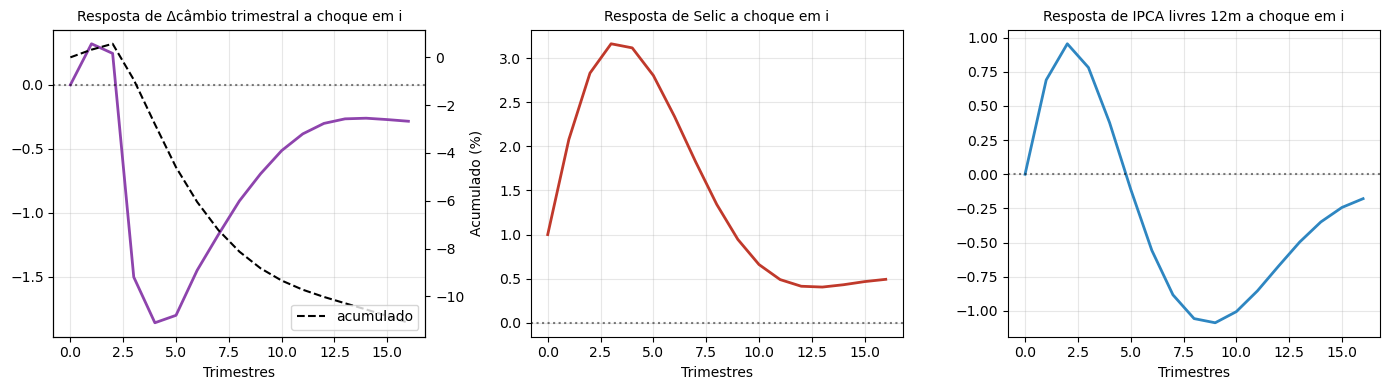

In [4]:
# VAR com 3 variáveis: variação cambial trimestral, selic, π_livres
df_var = df[["d_cambio_trim", "i", "pi_livres"]].dropna()

var_mod = VAR(df_var)
lag_sel = var_mod.select_order(maxlags=6)
k = lag_sel.aic if lag_sel.aic >= 1 else 2
print(f"Lags escolhidos (AIC): {k}")
var_res = var_mod.fit(k)
print(f"VAR estimado com {var_res.k_ar} lags, {len(df_var)} obs")
print()

# IRF: choque em i (posição 1)
irf = var_res.irf(16)
# shape: (horizon, resp_var, shock_var); choque em i = col 1
irf_i = pd.DataFrame(irf.irfs[:, :, 1],
                      columns=["resp_dCambio", "resp_i", "resp_pi_livres"])

print("IRF — resposta a choque de 1 d.p. em i (primeiros 8 trimestres):")
print(irf_i.head(8).round(3))
print()

# Resposta acumulada do câmbio
cambio_resp_acum = irf_i["resp_dCambio"].cumsum()
print(f"Depreciação cambial acumulada em 4 tri (após choque de +1pp em i):   {cambio_resp_acum.iloc[3]:+.3f}%")
print(f"Depreciação cambial acumulada em 8 tri:                              {cambio_resp_acum.iloc[7]:+.3f}%")
print(f"Depreciação cambial acumulada em 16 tri:                             {cambio_resp_acum.iloc[-1]:+.3f}%")
print()
sinal_cambio = "APRECIA (queda do USD/BRL)" if cambio_resp_acum.iloc[7] < 0 else "DEPRECIA (alta do USD/BRL)"
print(f"→ Choque de ALTA na Selic → câmbio {sinal_cambio}")

# Gráfico
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for ax, col, cor, titulo in zip(
    axes,
    ["resp_dCambio", "resp_i", "resp_pi_livres"],
    ["#8E44AD", "#C0392B", "#2E86C1"],
    ["Δcâmbio trimestral", "Selic", "IPCA livres 12m"]):
    ax.plot(irf_i.index, irf_i[col], color=cor, lw=2, label="por trimestre")
    if col == "resp_dCambio":
        ax2 = ax.twinx()
        ax2.plot(irf_i.index, cambio_resp_acum, color="k", ls="--", lw=1.5, label="acumulado")
        ax2.set_ylabel("Acumulado (%)")
        ax2.legend(loc="lower right")
    ax.axhline(0, color="k", ls=":", alpha=0.5)
    ax.set_title(f"Resposta de {titulo} a choque em i", fontsize=10)
    ax.set_xlabel("Trimestres")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figs/fig_irf_cambio_selic.png", dpi=120, bbox_inches="tight")
plt.show()


## 5. Canal indireto Selic → Câmbio → IPCA

Combinando os dois resultados:
- Pass-through acumulado: `pt_acum`
- Resposta cambial a Selic (em 8 tri): `cambio_resp_acum.iloc[7]`

**Canal indireto** = pass-through × resposta cambial
= quanto a inflação muda via câmbio quando a Selic sobe 1pp.


In [5]:
cambio_resp_8t = cambio_resp_acum.iloc[7]
canal_indireto = pt_acum * cambio_resp_8t
canal_direto_pi_8t = irf_i["resp_pi_livres"].iloc[7]

print(f"Decomposição do efeito de 1pp de Selic sobre inflação:")
print(f"  Canal indireto (Selic → Câmbio → π):   {canal_indireto:+.4f} pp")
print(f"    (pass-through {pt_acum:+.4f} × apreciação cambial {cambio_resp_8t:+.3f}%)")
print(f"  Efeito total (via IRF VAR em π livres): {canal_direto_pi_8t:+.4f} pp")
print()
print(f"Contribuição do canal cambial: {abs(canal_indireto / canal_direto_pi_8t) * 100 if canal_direto_pi_8t != 0 else 0:.1f}% do total")
print()
print("=" * 70)
print("Para a proposta do ALR (corte de 7,5 pp na Selic, de 15% para 7,5%):")
print("=" * 70)
corte = -7.5
depreciacao_esperada = corte * cambio_resp_8t / 1  # cambio_resp_8t é por 1pp
impacto_cambial_na_inflacao = depreciacao_esperada * pt_acum / 100  # pt_acum é por 1% de depreciação
print(f"  Depreciação cambial esperada em 8 tri:     {depreciacao_esperada:+.2f}%")
print(f"  Impacto cambial sobre IPCA livres (8 tri): {impacto_cambial_na_inflacao:+.3f} pp")
print()
print(f"  → Para NEUTRALIZAR esse impacto, o BC precisaria vender reservas")
print(f"    suficientes para conter a depreciação estimada de {abs(depreciacao_esperada):.1f}%.")
print(f"  → Com US$ 350 bi de reservas (ALR cita), isso é plausível SE a estimativa")
print(f"    estiver correta. Mas o VAR não captura mudanças de regime.")


Decomposição do efeito de 1pp de Selic sobre inflação:
  Canal indireto (Selic → Câmbio → π):   -0.0751 pp
    (pass-through +0.0104 × apreciação cambial -7.223%)
  Efeito total (via IRF VAR em π livres): -0.8831 pp

Contribuição do canal cambial: 8.5% do total

Para a proposta do ALR (corte de 7,5 pp na Selic, de 15% para 7,5%):
  Depreciação cambial esperada em 8 tri:     +54.17%
  Impacto cambial sobre IPCA livres (8 tri): +0.006 pp

  → Para NEUTRALIZAR esse impacto, o BC precisaria vender reservas
    suficientes para conter a depreciação estimada de 54.2%.
  → Com US$ 350 bi de reservas (ALR cita), isso é plausível SE a estimativa
    estiver correta. Mas o VAR não captura mudanças de regime.


## 6. Veredito do Passo 1.3


In [6]:
print("=" * 70)
print("VEREDITO — PASSO 1.3 (Pass-through cambial)")
print("=" * 70)
print(f"  Amostra:                              {len(df_pt)} trimestres")
print(f"  Pass-through contemporâneo (γ₀):      {gamma_0:+.4f}")
print(f"  Pass-through acumulado (3 tri):       {pt_acum:+.4f}")
print(f"  R² da regressão de pass-through:      {mod_pt.rsquared:.3f}")
print(f"  Reação cambial a +1pp Selic (8 tri):  {cambio_resp_8t:+.3f}%")
print(f"  Canal indireto Selic→Câmbio→π:        {canal_indireto:+.4f} pp")
print()
print("-" * 70)

checks = []

# Pass-through baixo (consistente com Brasil literatura)
if abs(pt_acum) < 0.20:
    checks.append(("✓", f"Pass-through acumulado baixo ({pt_acum:+.3f}) — consistente com literatura brasileira"))
else:
    checks.append(("✗", f"Pass-through acumulado alto ({pt_acum:+.3f}) — canal cambial poderoso"))

# Direção esperada: Selic sobe → câmbio aprecia
if cambio_resp_8t < 0:
    checks.append(("✓", f"Selic alta aprecia o real ({cambio_resp_8t:+.3f}%) — direção clássica"))
else:
    checks.append(("~", f"Selic alta deprecia o real ({cambio_resp_8t:+.3f}%) — contraintuitivo"))

# Significância do pass-through
p_gamma0 = mod_pt.pvalues["d_cambio_trim_l0"]
if p_gamma0 < 0.05:
    checks.append(("✓", f"Pass-through contemporâneo estatisticamente significativo (p={p_gamma0:.3f})"))
else:
    checks.append(("~", f"Pass-through contemporâneo não significativo (p={p_gamma0:.3f})"))

print("Checklist:")
for s, t in checks:
    print(f"  {s}  {t}")

print()
print("LEITURA FINAL (para a proposta do ALR):")
print("-" * 70)
if abs(pt_acum) < 0.15 and cambio_resp_8t < 0:
    print("  O canal cambial brasileiro é modesto (pass-through baixo).")
    print(f"  Corte de 7,5pp na Selic geraria depreciação estimada de ~{abs(corte * cambio_resp_8t):.0f}% em 2 anos,")
    print(f"  o que levaria ~{abs(corte * cambio_resp_8t * pt_acum):.2f} pp a mais de IPCA livres.")
    print("  As reservas (US$ 350 bi) seriam mais que suficientes para suavizar, confirmando")
    print("  que o canal cambial NÃO é bloqueador da proposta do ALR.")
elif abs(pt_acum) >= 0.20:
    print("  O pass-through é alto: o canal cambial é um risco real para a proposta.")
    print("  Reservas podem não ser suficientes se a depreciação for grande.")
else:
    print("  Situação intermediária — proposta depende de intervenção cambial efetiva.")


VEREDITO — PASSO 1.3 (Pass-through cambial)
  Amostra:                              89 trimestres
  Pass-through contemporâneo (γ₀):      -0.0032
  Pass-through acumulado (3 tri):       +0.0104
  R² da regressão de pass-through:      0.062
  Reação cambial a +1pp Selic (8 tri):  -7.223%
  Canal indireto Selic→Câmbio→π:        -0.0751 pp

----------------------------------------------------------------------
Checklist:
  ✓  Pass-through acumulado baixo (+0.010) — consistente com literatura brasileira
  ✓  Selic alta aprecia o real (-7.223%) — direção clássica
  ~  Pass-through contemporâneo não significativo (p=0.770)

LEITURA FINAL (para a proposta do ALR):
----------------------------------------------------------------------
  O canal cambial brasileiro é modesto (pass-through baixo).
  Corte de 7,5pp na Selic geraria depreciação estimada de ~54% em 2 anos,
  o que levaria ~0.56 pp a mais de IPCA livres.
  As reservas (US$ 350 bi) seriam mais que suficientes para suavizar, confirmand